# Esercizio 2) LS su dati reali

## Consegna: 

Leggi i dati contenuti nel file `Life_Expectancy_Data_Updated.csv` e salvali in un dataframe.
Considera la colonna `Life_expectancy` e una seconda variabile numerica a scelta (possibilmente che correli con la prima).
Calcola un buon modello di regressione per predire `Life_expectancy` (feature dipendente, `y`) a partire da un'altra variabile del dataset (feature indipendente, `x`).

In particolare:
- importa i dati dal file con la funzione di `pandas`;
- guarda alle dimensioni del dataset e alle sue prime righe;
- scarta le variabili non numeriche con `drop()`;
- utilizzando la funzione `scatter_matrix` di `pandas.plotting`, guarda se e come correlano le variabili del dataset fra loro e individua di conseguenza una buona feature `x`:
- estrai dal dataframe i dati per la regressione (variabile indipendente `x` e variabile dipendente `y`), poi visualizza i punti (x,y) con lo scatterplot.

Ora:
- separa i punti per train e test;
- fissa il grado del modello di regressione e costruisci la matrice di Vandermonde opportuna a partire dai punti di *training*;
- risolvi la regressione tramite i minimi quadrati implementati da `np.linalg.lstsq`, provando modelli di grado 1, 2, 3 e 8;
- visualizza il modello di regressione sull'intero dominio $ x \in [0, 150]$, insieme ai punti di training;
- calcola le predizioni per i punti di *testing* e visualizza il modello di regressione coi punti di testing;
- analizza i residui e calcola le metriche di R-quadro e MSE.

Ripeti la regressione provando una altra feature `x` come variabile indipendente.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



## Caricamento dei dati

In [3]:
df=pd.read_csv("Life_Expectancy_Data_Updated.csv")

print(type(df))

<class 'pandas.DataFrame'>


In [4]:
print( df.shape )

(2864, 21)


In [5]:
print("Prime righe del dataframe:")
print(df.head())

Prime righe del dataframe:
   Country          Region  Year  Infant_deaths  Under_five_deaths  \
0  Turkiye     Middle East  2015           11.1               13.0   
1    Spain  European Union  2015            2.7                3.3   
2    India            Asia  2007           51.5               67.9   
3   Guyana   South America  2006           32.8               40.5   
4   Israel     Middle East  2012            3.4                4.3   

   Adult_mortality  Alcohol_consumption  Hepatitis_B  Measles   BMI  ...  \
0         105.8240                 1.32           97       65  27.8  ...   
1          57.9025                10.35           97       94  26.0  ...   
2         201.0765                 1.57           60       35  21.2  ...   
3         222.1965                 5.68           93       74  25.3  ...   
4          57.9510                 2.89           97       89  27.0  ...   

   Diphtheria  Incidents_HIV  GDP_per_capita  Population_mln  \
0          97           0.08   

In [6]:
df.info()  # per vededre Non-Null Count e Tipi di dato

<class 'pandas.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      2864 non-null   str    
 1   Region                       2864 non-null   str    
 2   Year                         2864 non-null   int64  
 3   Infant_deaths                2864 non-null   float64
 4   Under_five_deaths            2864 non-null   float64
 5   Adult_mortality              2864 non-null   float64
 6   Alcohol_consumption          2864 non-null   float64
 7   Hepatitis_B                  2864 non-null   int64  
 8   Measles                      2864 non-null   int64  
 9   BMI                          2864 non-null   float64
 10  Polio                        2864 non-null   int64  
 11  Diphtheria                   2864 non-null   int64  
 12  Incidents_HIV                2864 non-null   float64
 13  GDP_per_capita               

Mantengo solo le variabili numeriche

In [7]:
df_orig = df.copy() #   creo copia indipendente

In [8]:
df = df.drop("Country", axis=1)
df = df.drop("Region", axis=1)
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Year                         2864 non-null   int64  
 1   Infant_deaths                2864 non-null   float64
 2   Under_five_deaths            2864 non-null   float64
 3   Adult_mortality              2864 non-null   float64
 4   Alcohol_consumption          2864 non-null   float64
 5   Hepatitis_B                  2864 non-null   int64  
 6   Measles                      2864 non-null   int64  
 7   BMI                          2864 non-null   float64
 8   Polio                        2864 non-null   int64  
 9   Diphtheria                   2864 non-null   int64  
 10  Incidents_HIV                2864 non-null   float64
 11  GDP_per_capita               2864 non-null   int64  
 12  Population_mln               2864 non-null   float64
 13  Thinness_ten_nineteen_years  

## Analisi delle variabili disponibili e visualizzazioni

#### 1. Tutte le variabili numeriche

Vediamo tutte le combinazioni di scatterplot 2D con `scatter_matrix` che fa parte di pandas. Più precisamente, lo troviamo in `pandas.plotting` che è incluso in pandas (quindi non va installato separatamente e ci basta importare la funzione che ci serve).

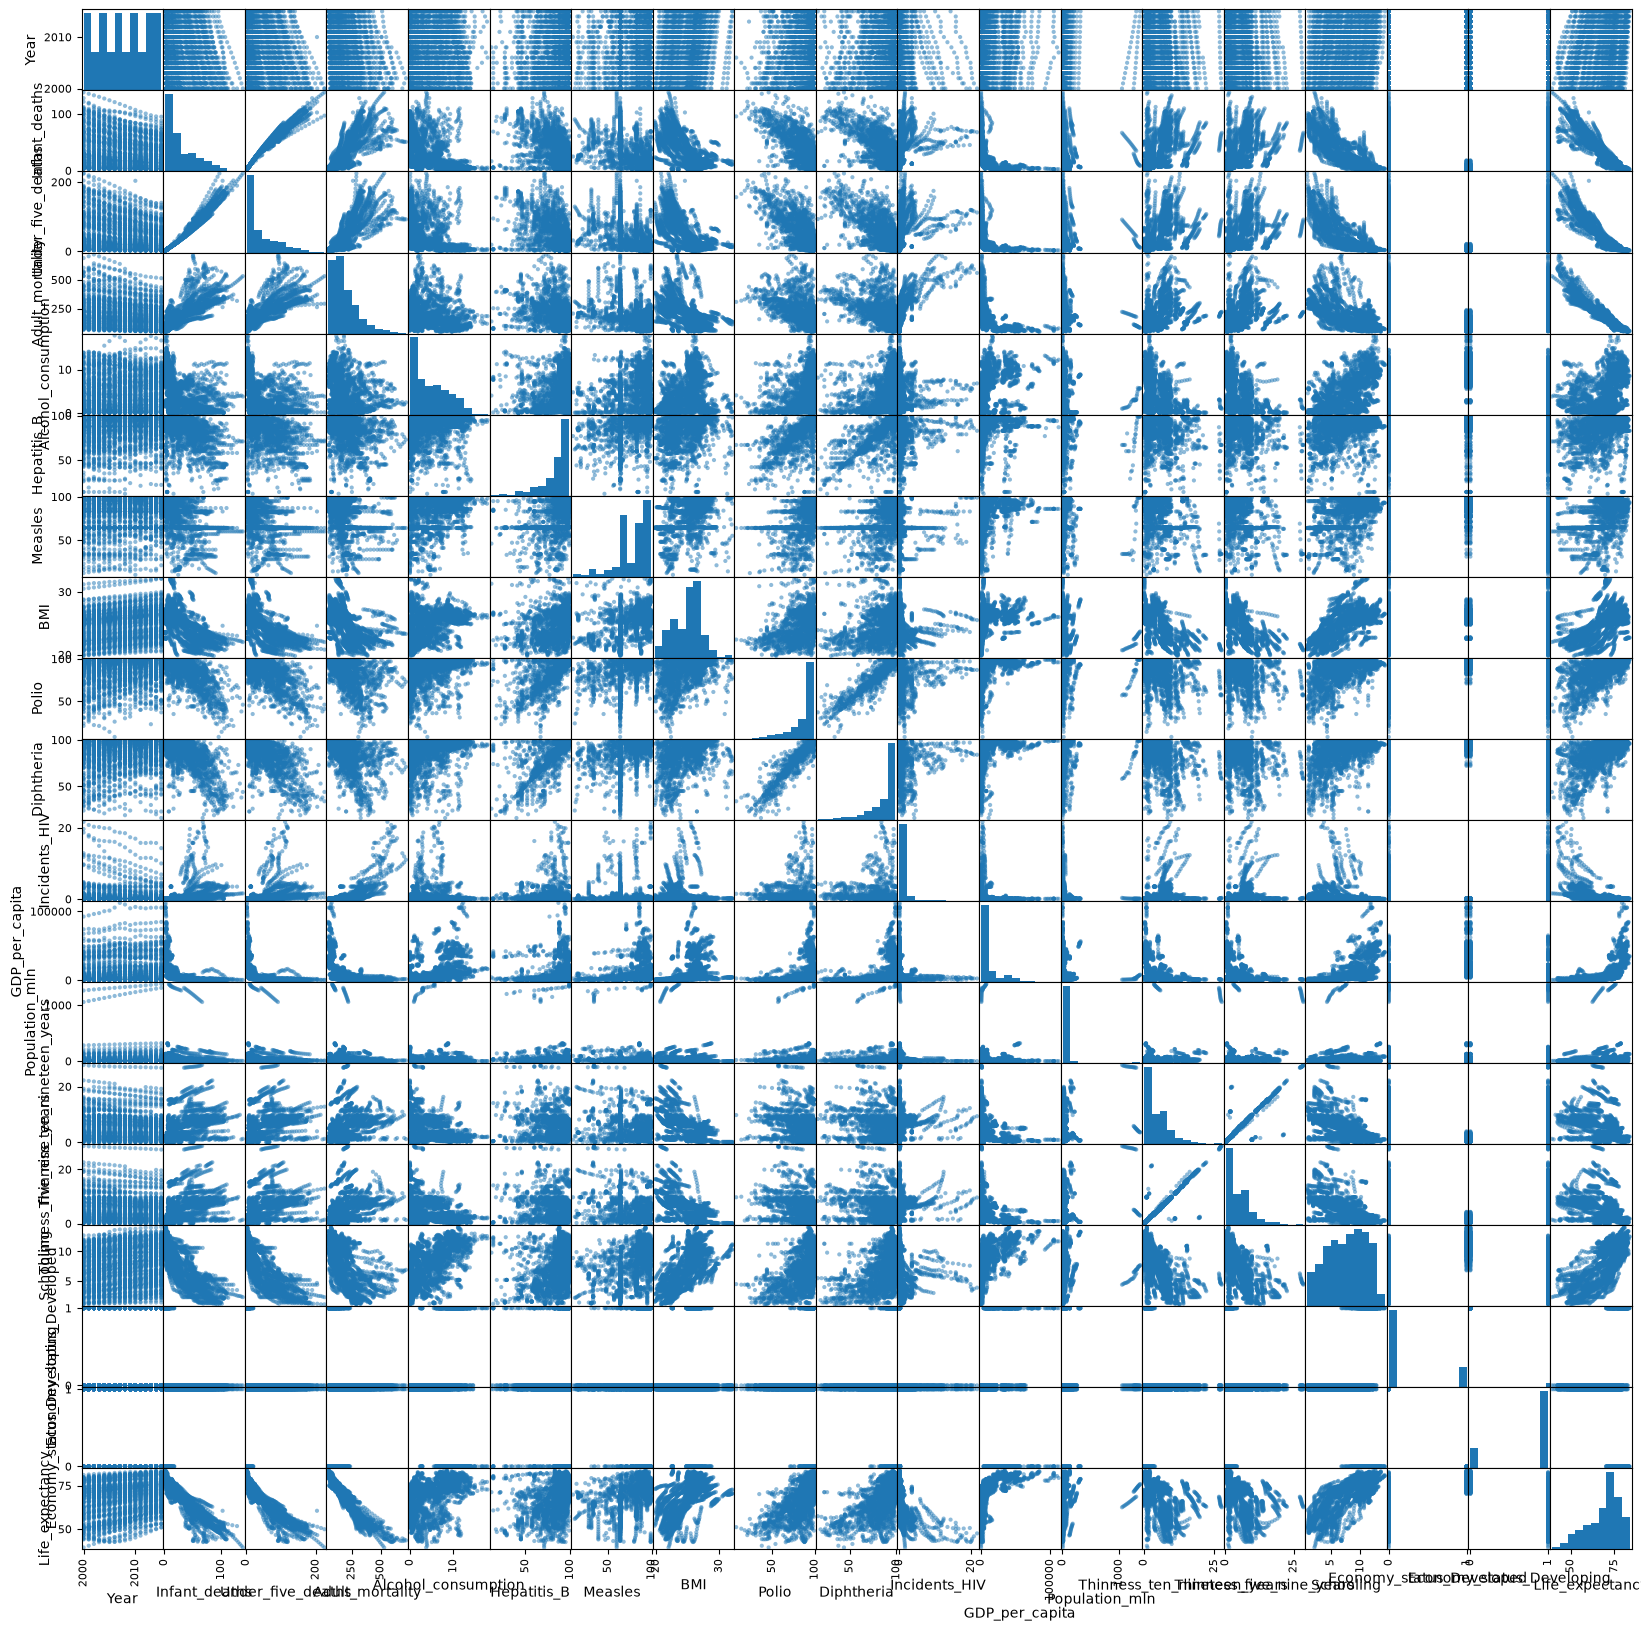

In [9]:
from pandas.plotting import scatter_matrix

scatter_matrix(df, figsize=(20, 20), diagonal="hist")
plt.show()

#### 2. La variabile dipendente (da predire)


In [11]:
print( df["Life_expectancy"][:15])

0     76.5
1     82.8
2     65.4
3     67.0
4     81.7
5     78.2
6     71.2
7     71.2
8     71.9
9     68.7
10    74.2
11    79.8
12    72.3
13    68.3
14    81.5
Name: Life_expectancy, dtype: float64


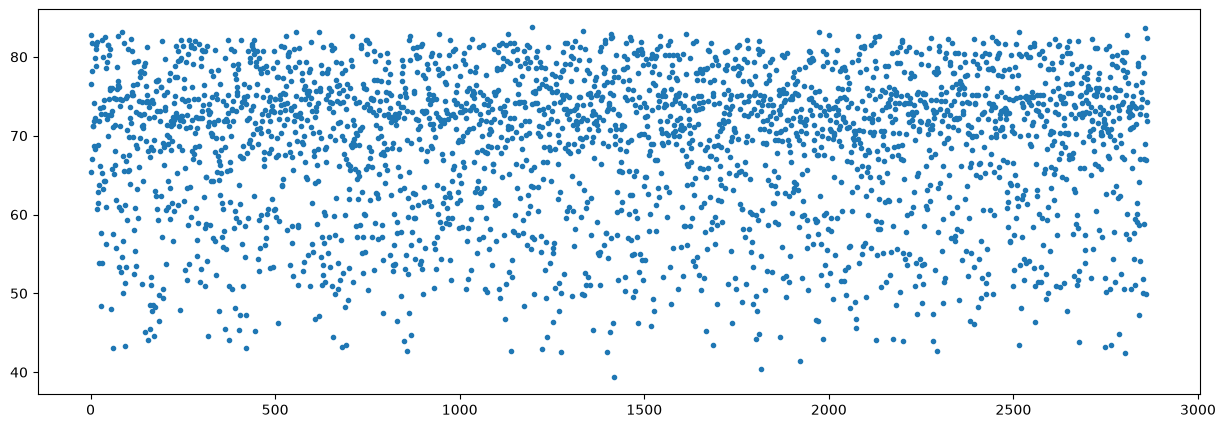

In [12]:
y = np.array (df["Life_expectancy"])

plt.figure(figsize=(15,5))
plt.plot(y, '.')
plt.show()

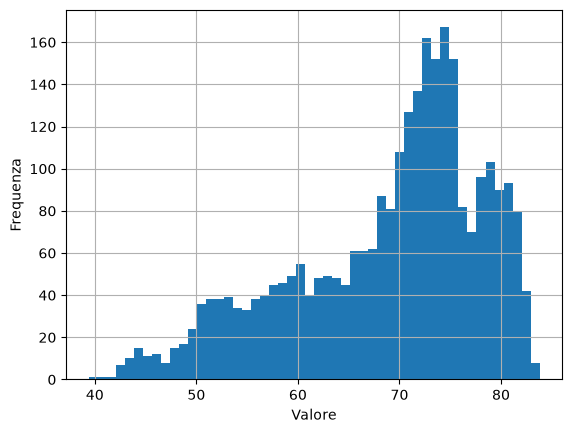

In [13]:
df["Life_expectancy"].hist(bins=50)

plt.xlabel("Valore")
plt.ylabel("Frequenza")
plt.show()

#### 3. Alcune variabili 

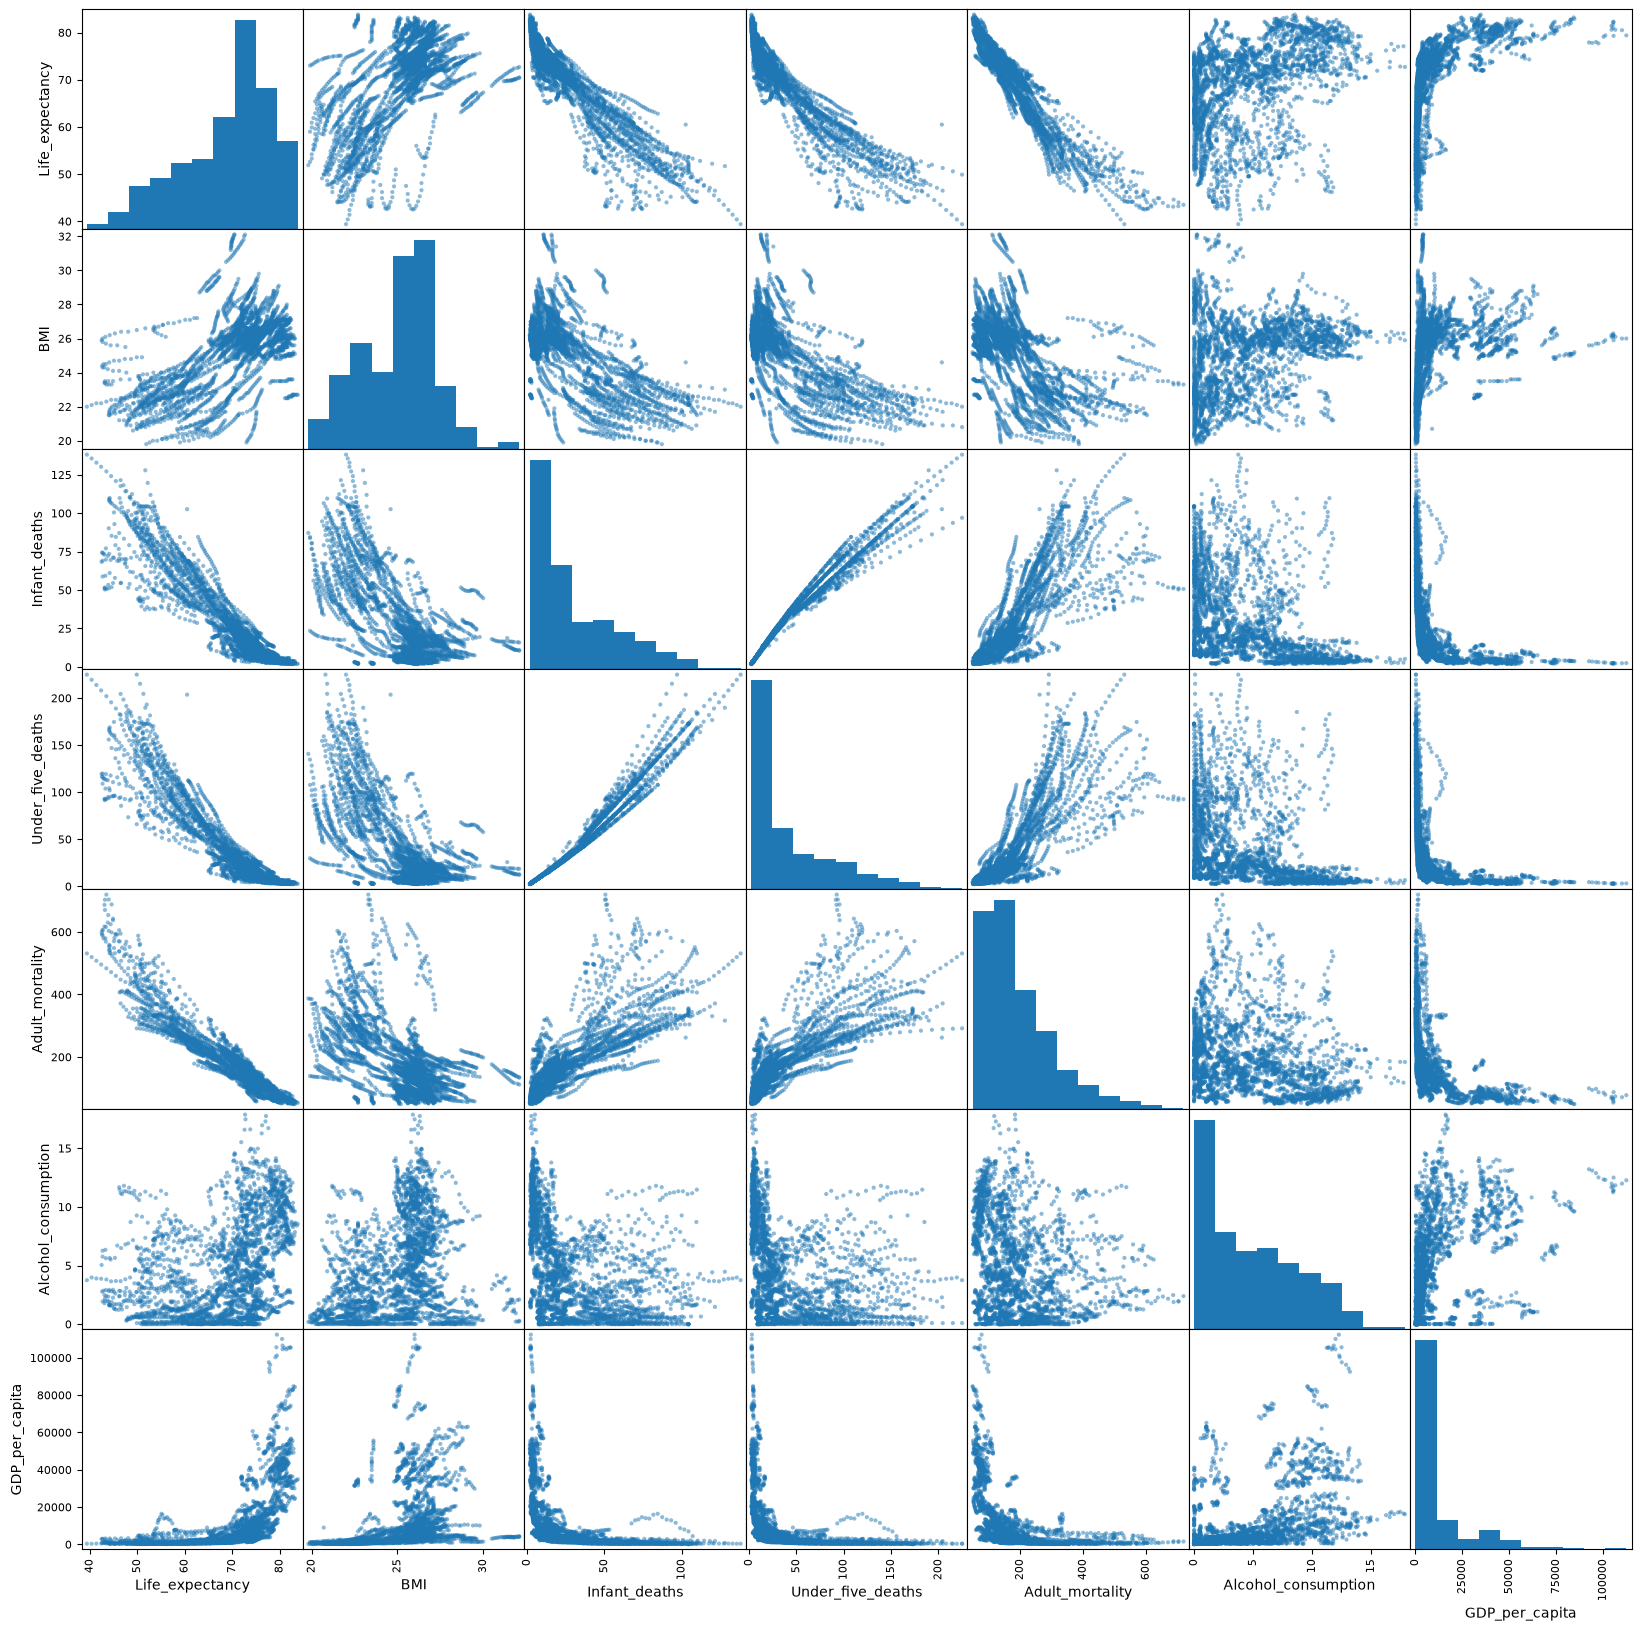

In [10]:
DF = df[["Life_expectancy", "BMI", "Infant_deaths", "Under_five_deaths", "Adult_mortality", "Alcohol_consumption", "GDP_per_capita"]].copy()

scatter_matrix(DF, figsize=(20, 20), diagonal="hist")
plt.show()

<Axes: >

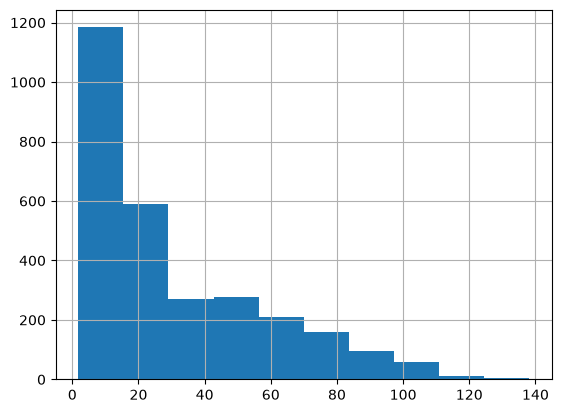

In [14]:
x = np.array(DF["Infant_deaths"] ) 

DF["Infant_deaths"].hist()

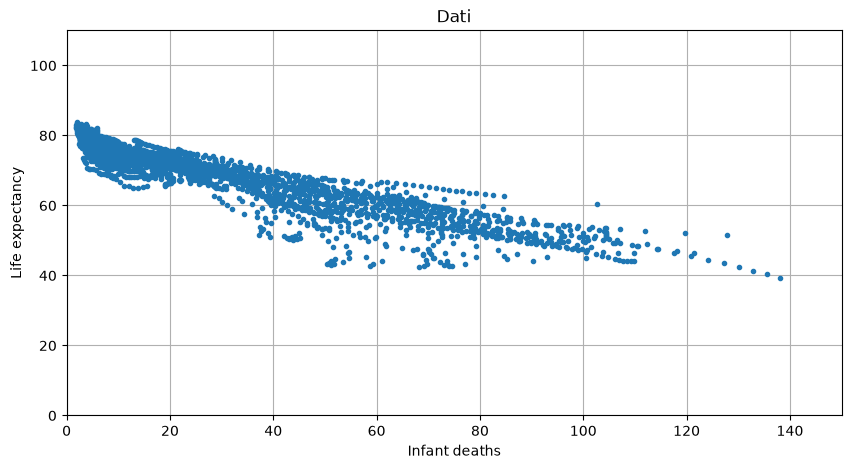

In [15]:
plt.figure(figsize=(10, 5))  
plt.plot(x, y, '.')
plt.title('Dati')
plt.xlabel('Infant deaths')
plt.ylabel('Life expectancy')
plt.xlim([0, 150])
plt.ylim([0, 110])
plt.grid()
plt.show()

## Train = LS per regressione

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
# Divido il dataset in set di addestramento e di test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print( x_train.shape)
print( x_test.shape)

(2291,)
(573,)


Creazione della matrice del sistema

In [30]:
# Grado del polinomio
grado = 8

# Matrice del modello
m = len(x_train)
A = np.zeros((m, grado + 1))

for j in range(grado + 1):
    A[:, j] = x_train**j

print(A.shape)    

(2291, 9)


Risoluzione con LSTSQ

In [32]:
beta_star, residui, rango, valori_singolari = np.linalg.lstsq(A, y_train, rcond=None)
print('Soluzione LSQ:', np.round(beta_star, 4))

Soluzione LSQ: [ 0.      0.      0.      0.      0.0002 -0.      0.     -0.      0.    ]


In [20]:
beta0 = beta_star[0]
beta1 = beta_star[1]
print(f"beta0 = {beta0:.4f}")
print(f"beta1 = {beta1:.4f}")

x_vec = np.linspace(0,150, 200)

if grado==1:
    y_vec = beta0 + beta1*x_vec
else: # grado ==2
    beta2 = beta_star[2]
    print(f"beta2 = {beta2:.4f}")
    y_vec = beta0 + beta1*x_vec + beta2*x_vec**2


beta0 = 78.3991
beta1 = -0.3147


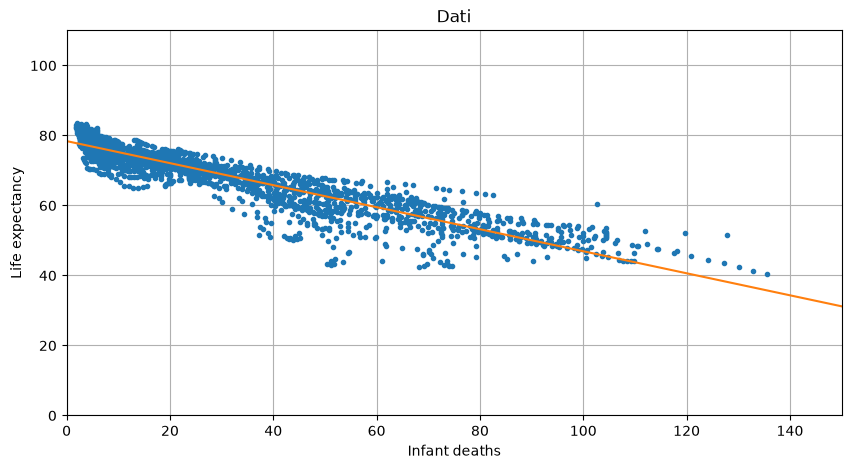

In [37]:
plt.figure(figsize=(10, 5))  
plt.plot(x_train, y_train, '.')
plt.plot(x_vec, y_vec, '-')
plt.title('Dati')
plt.xlabel('Infant deaths')
plt.ylabel('Life expectancy')
plt.xlim([0, 150])
plt.ylim([0, 110])
plt.grid()
plt.show()

## Test 

Creo la nuova matrice A coi dati di testing

In [ ]:
# Matrice del modello
m = len(x_test)
A_test = np.zeros((m, grado + 1))

# to do ...

print(A_test.shape)    

In [ ]:
# y_pred = ...

Metodo alternativo: implemento la formula del modello

In [23]:
m = len(x_test)
y_pred2 = np.zeros_like(y_test)

for k in range (m):
    for j in range(grado + 1):
        # print(f"{k}    {j}")
        y_pred2[k] = y_pred2[k] + beta_star[j]*x_test[k]**j

print(y_test[:10])
print(y_pred2[:10])  

[72.  81.3 62.7 55.4 79.  82.1 81.4 61.1 69.8 81.4]
[73.8988702  77.17173878 63.2935172  51.64965783 77.04585922 77.36055812
 77.4234979  57.8492262  74.18209921 77.67525702]


#### 1. Residui

In [ ]:
# TO DO 

In [ ]:
# print(.....) 


#### 2. R quadro
L'R quadro (R² o coefficiente di determinazione) è un indice statistico che misura quanta varianza della variabile dipendente (y) è spiegata dalle variabili indipendenti (X) in un modello di regressione.

Scala dei valori

- 0 (o 0%): Il modello non spiega alcuna variabilità dei dati; la previsione non è migliore della semplice media.
- 1 (o 100%): Spiegazione perfetta; tutti i punti cadono esattamente sulla retta o curva di regressione.
- Valori negativi (R² < 0): Si verificano quando il modello è peggio del semplice utilizzo della media come predittore (di solito a causa di assenza di intercetta o specifiche formule).

In [24]:
from sklearn.metrics import r2_score

print("R-squared:", r2_score(y_test, y_pred2))


R-squared: 0.8373578190511807


#### 3. MSE

L'MSE (Mean Squared Error, in italiano Errore Quadratico Medio) è un'ulteriore metrica utilizzata in statistica e nel machine learning per misurare la precisione di un modello di regressione. Calcola la differenza tra ogni valore reale e il relativo valore previsto, la eleva al quadrato e poi calcola la media di tutti i risultati.

Scala dei valori: 
- più il valore dell'MSE è basso, migliore è il modello: un MSE pari a 0 indica una precisione perfetta.
- non esiste un upper bound (limite massimo) predefinito dell'MSE: l'entità di ogni errore dipende dal range dei valori di y. Inoltre, elevando al quadrato gli errori, i valori anomali (outliers) vengono penalizzati molto pesantemente rispetto agli errori piccoli e l'MSE cresce.

In [25]:
from sklearn.metrics import mean_squared_error

print("Mean Squared Error:", mean_squared_error(y_test, y_pred2))


Mean Squared Error: 13.497870389339836


In [ ]:
print('Somma(residui)**2 / n_test:\t', np.dot(r, r)/ y_test.size)